# Used Car Price Regression

Data Science, Semester 3, Plaksha University (linear regression lab).

Part 1 computes simple linear regression by hand. Part 2 builds a multiple linear regression model that predicts used-car prices from 4,009 listings, with feature engineering, a held-out test set and regression diagnostics.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

plt.rcParams["figure.dpi"] = 100

## Part 1: Simple linear regression by hand

For points $(x_i, y_i)$ the least-squares line $\hat y = b_0 + b_1 x$ has

$$b_1 = \frac{\sum (x_i - \bar x)(y_i - \bar y)}{\sum (x_i - \bar x)^2}, \qquad b_0 = \bar y - b_1 \bar x, \qquad R^2 = 1 - \frac{RSS}{TSS}$$

slope b1 = 0.840, intercept b0 = 0.500
RSS = 0.772, TSS = 7.828, R^2 = 0.9014


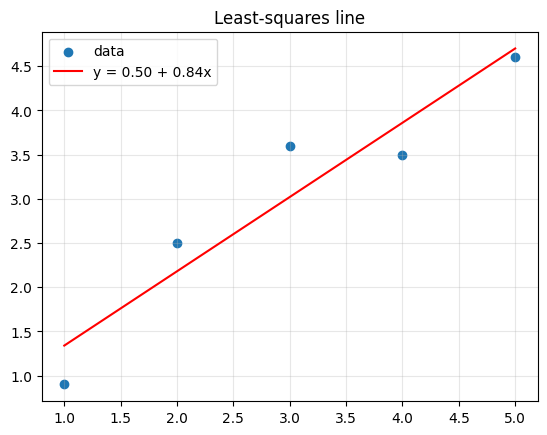

In [2]:
x = [1, 2, 3, 4, 5]
y = [0.9, 2.5, 3.6, 3.5, 4.6]

x_mean, y_mean = sum(x) / len(x), sum(y) / len(y)
b1 = sum((xi - x_mean) * (yi - y_mean) for xi, yi in zip(x, y)) / sum((xi - x_mean) ** 2 for xi in x)
b0 = y_mean - b1 * x_mean
y_hat = [b0 + b1 * xi for xi in x]
rss = sum((yi - yh) ** 2 for yi, yh in zip(y, y_hat))
tss = sum((yi - y_mean) ** 2 for yi in y)

print(f"slope b1 = {b1:.3f}, intercept b0 = {b0:.3f}")
print(f"RSS = {rss:.3f}, TSS = {tss:.3f}, R^2 = {1 - rss / tss:.4f}")

plt.scatter(x, y, label="data")
plt.plot(x, y_hat, "r", label=f"y = {b0:.2f} + {b1:.2f}x")
plt.legend(); plt.grid(alpha=0.3); plt.title("Least-squares line")
plt.show()

The slope of 0.84 means $y$ rises by 0.84 for each unit of $x$. An $R^2$ of 0.90 means the line explains 90% of the variation in $y$.

## Part 2: Used car prices

### Cleaning and feature engineering

The raw columns are text (`"51,000 mi."`, `"$10,300"`, `"300.0HP 3.7L V6 ..."`). The following features are extracted:

- `age` = 2024 - model year,
- `milage` as a number,
- `horsepower` and engine size in litres, parsed from the engine description,
- automatic or manual transmission,
- accident history,
- fuel type, and brand (the 20 most common brands are kept; the rest become "Other").

The raw `model` and `engine` strings have 1,898 and 1,146 distinct values, so they are not one-hot encoded. With almost one column per car, the model would memorise the training data.

In [3]:
cars = pd.read_csv("data/used_cars_dataset.csv")
print(cars.shape)

def first_number(s):
    m = re.search(r"(\d[\d,]*\.?\d*)", str(s))
    return float(m.group(1).replace(",", "")) if m else np.nan

df = pd.DataFrame({
    "price": cars["price"].map(first_number),
    "age": 2024 - cars["model_year"],
    "milage": cars["milage"].map(first_number),
    "horsepower": cars["engine"].str.extract(r"(\d+\.?\d*)HP", expand=False).astype(float),
    "litres": cars["engine"].str.extract(r"(\d+\.?\d*)\s*L", expand=False).astype(float),
    "manual": cars["transmission"].str.contains(r"M/T|Manual", case=False, na=False).astype(int),
    "accident": (cars["accident"] == "At least 1 accident or damage reported").astype(int),
    "fuel_type": cars["fuel_type"].replace({"–": np.nan, "not supported": np.nan}).fillna("Unknown"),
    "brand": cars["brand"].where(cars["brand"].isin(cars["brand"].value_counts().index[:20]), "Other"),
})
print("missing horsepower:", df["horsepower"].isna().sum(), "| missing litres:", df["litres"].isna().sum())
df["horsepower"] = df["horsepower"].fillna(df["horsepower"].median())
df["litres"] = df["litres"].fillna(df["litres"].median())

# Remove extreme listings (top 1% of prices) that dominate a squared-error fit
df = df[df["price"] < df["price"].quantile(0.99)].reset_index(drop=True)
df["log_price"] = np.log(df["price"])
df.describe().round(1)

(4009, 9)
missing horsepower: 808 | missing litres: 217


,price,age,milage,horsepower,litres,manual,accident,log_price
count,3968.0,3968.0,3968.0,3968.0,3968.0,3968.0,3968.0,3968.0
mean,39550.0,8.5,65339.6,326.9,3.7,0.1,0.2,10.3
std,34833.8,6.1,52201.9,108.7,1.4,0.3,0.4,0.8
min,2000.0,0.0,100.0,70.0,0.6,0.0,0.0,7.6
25%,17000.0,4.0,23635.2,268.0,2.5,0.0,0.0,9.7
50%,30969.5,7.0,53575.0,310.0,3.5,0.0,0.0,10.3
75%,48998.2,12.0,94650.8,381.0,4.6,0.0,0.0,10.8
max,269991.0,50.0,405000.0,1020.0,8.3,1.0,1.0,12.5


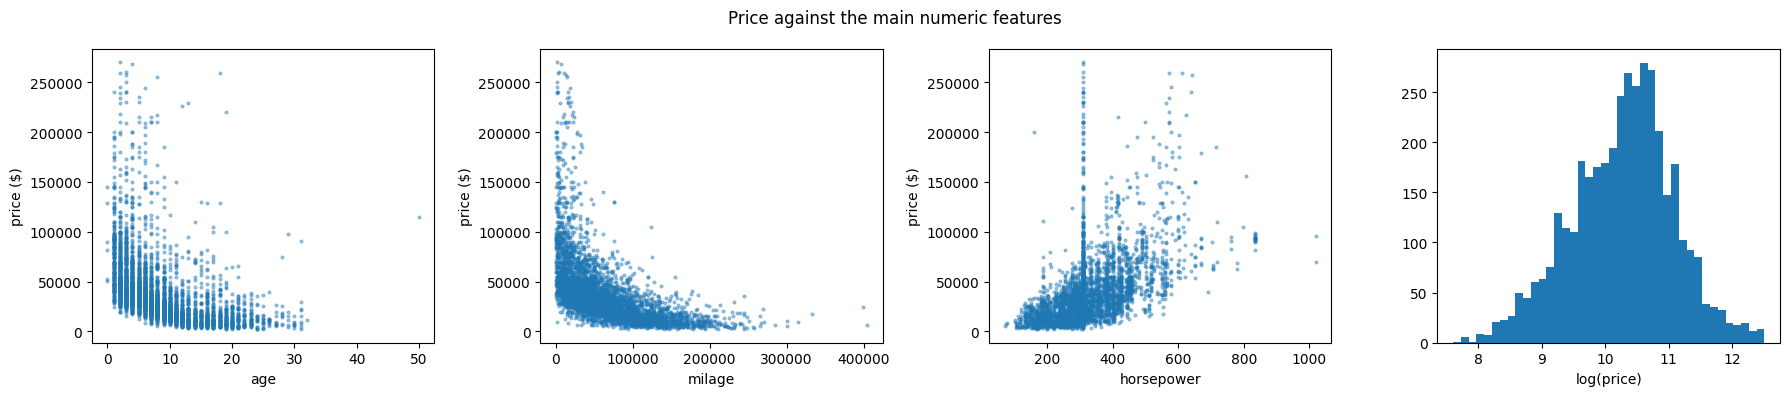

,correlation with log(price)
log_price,1.000
age,-0.649
milage,-0.714
horsepower,0.581
litres,0.230
manual,-0.088
accident,-0.268


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["age", "milage", "horsepower"]):
    ax.scatter(df[col], df["price"], s=4, alpha=0.4)
    ax.set_xlabel(col); ax.set_ylabel("price ($)")
axes[3].hist(df["log_price"], bins=40)
axes[3].set_xlabel("log(price)")
plt.suptitle("Price against the main numeric features")
plt.tight_layout()
plt.savefig("images/eda.png")
plt.show()
df[["log_price", "age", "milage", "horsepower", "litres", "manual", "accident"]].corr()["log_price"].round(3).to_frame("correlation with log(price)")

Price falls with age and mileage and rises with horsepower. Prices are right-skewed, so the model predicts $\log(\text{price})$. A coefficient then means a percentage change in price.

### Multiple linear regression with a held-out test set

In [5]:
X = pd.get_dummies(df.drop(columns=["price", "log_price"]), columns=["fuel_type", "brand"], drop_first=True, dtype=float)
y = df["log_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlr = LinearRegression().fit(X_train, y_train)
pred_test = mlr.predict(X_test)

def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

r2_train = mlr.score(X_train, y_train)
r2_test = r2_score(y_test, pred_test)
n, p = X_test.shape
mae_dollars = mean_absolute_error(np.exp(y_test), np.exp(pred_test))
print(f"features: {X.shape[1]}")
print(f"R^2 train = {r2_train:.3f}, R^2 test = {r2_test:.3f}, adjusted R^2 test = {adjusted_r2(r2_test, n, p):.3f}")
print(f"mean absolute error on test cars: ${mae_dollars:,.0f}")

features: 31
R^2 train = 0.791, R^2 test = 0.792, adjusted R^2 test = 0.784
mean absolute error on test cars: $10,328


In [6]:
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
summary = pd.DataFrame({"coef": ols.params, "p-value": ols.pvalues}).loc[["age", "milage", "horsepower", "litres", "manual", "accident"]]
units = {"age": (1, "per year"), "milage": (10000, "per 10,000 miles"), "horsepower": (10, "per 10 hp"),
         "litres": (1, "per litre"), "manual": (1, "manual vs automatic"), "accident": (1, "accident vs none")}
summary["effect on price"] = [f"{(np.exp(c * units[k][0]) - 1) * 100:+.1f}% {units[k][1]}" for k, c in summary["coef"].items()]
print(f"OLS on the training set: R^2 = {ols.rsquared:.3f}, adjusted R^2 = {ols.rsquared_adj:.3f}")
summary.round(6)

OLS on the training set: R^2 = 0.791, adjusted R^2 = 0.789


,coef,p-value,effect on price
age,-0.048417,0.0,-4.7% per year
milage,-0.000006,0.0,"-5.8% per 10,000 miles"
horsepower,0.001908,0.0,+1.9% per 10 hp
litres,0.120521,0.0,+12.8% per litre
manual,0.147963,0.0,+15.9% manual vs automatic
accident,-0.088123,0.0,-8.4% accident vs none


### Diagnostics

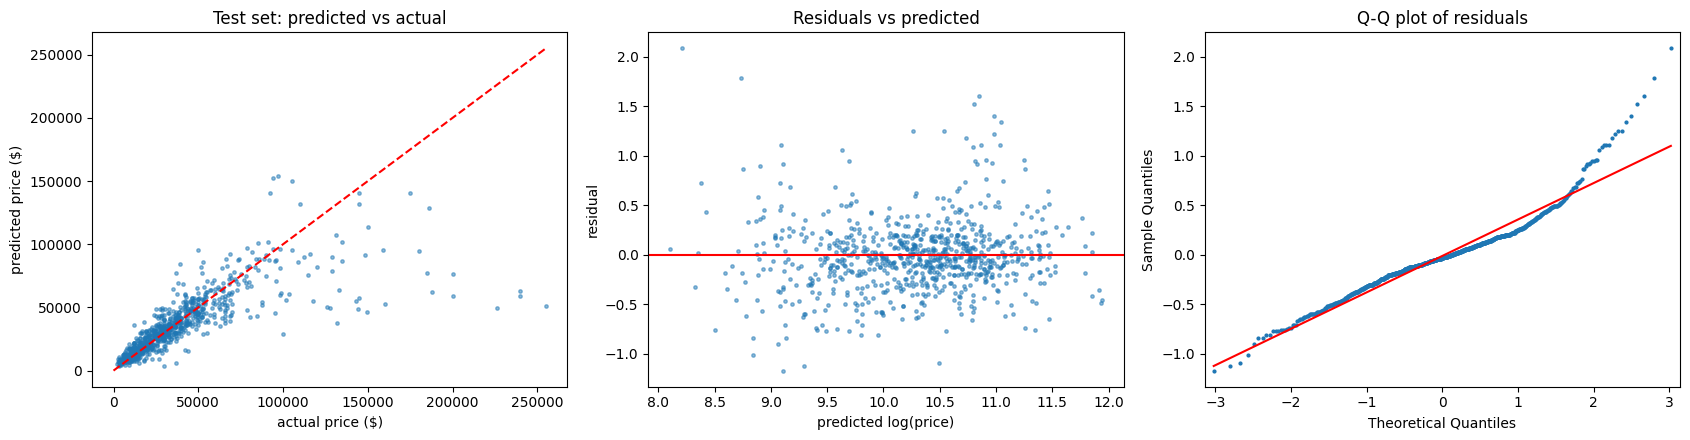

Durbin-Watson statistic: 1.96


In [7]:
residuals = y_test - pred_test
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(np.exp(y_test), np.exp(pred_test), s=6, alpha=0.5)
lim = [0, np.exp(y_test).max()]
axes[0].plot(lim, lim, "r--")
axes[0].set_xlabel("actual price ($)"); axes[0].set_ylabel("predicted price ($)"); axes[0].set_title("Test set: predicted vs actual")
axes[1].scatter(pred_test, residuals, s=6, alpha=0.5)
axes[1].axhline(0, color="r")
axes[1].set_xlabel("predicted log(price)"); axes[1].set_ylabel("residual"); axes[1].set_title("Residuals vs predicted")
sm.qqplot(residuals, line="s", ax=axes[2], markersize=2)
axes[2].set_title("Q-Q plot of residuals")
plt.tight_layout()
plt.savefig("images/diagnostics.png")
plt.show()
print("Durbin-Watson statistic:", round(durbin_watson(residuals), 3))

### Why the first version failed

The original notebook one-hot encoded every distinct `model` and `engine` string, which created thousands of columns for 4,009 cars. On the training data OLS reported an adjusted $R^2$ of 0.94. On the test set the same model scored $R^2 = 0.07$, and its "adjusted $R^2$" came out above 1, because there were more features than test rows. That is extreme overfitting: the model memorised individual cars instead of learning what drives price.

## Conclusions

- With about 30 meaningful features, the model explains about 80% of the variance in log price **on cars it has never seen**. The training and test $R^2$ are close, so it generalises.
- Each extra year of age lowers the price by about 5%, and each 10,000 miles by about 6%. A reported accident lowers it by about 8%. Each extra 10 hp adds about 2%. Manual cars come out about 16% dearer, probably because manual gearboxes in this dataset are mostly on sports cars.
- Typical error on unseen cars is about $10,000, because brand and engine size explain only part of the price of luxury and collector cars.
- The residuals are centred on zero with no strong pattern, and the Durbin-Watson statistic is close to 2 (no autocorrelation). The Q-Q plot shows heavier tails than normal, which comes from a few unusual listings.